In [28]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

# Load datasets directly from GitHub
base = "https://raw.githubusercontent.com/Break-Through-Tech/Telecom-1A-automated-telecom-support-nlp-agent-for-incident-management/main/"

df_train = pd.read_csv(base + "train.csv")
df_val = pd.read_csv(base + "validation.csv")
df_test = pd.read_csv(base + "test.csv")

# Verify datasets loaded successfully
print("Train:", df_train.shape)
print("Validation:", df_val.shape)
print("Test:", df_test.shape)

Train: (19056, 4)
Validation: (4764, 4)
Test: (3000, 4)


In [29]:

CLASS_ORDER = [
    "Device & Technical Support",
    "Network & Connectivity",
    "Billing & Payment",
    "Account & Plan Management",
    "Cancellation & Retention",
]

def get_class_weights(labels):
    classes = np.array(sorted(labels.unique()))
    weights = compute_class_weight(
        "balanced",
        classes=classes,
        y=labels
    )
    return dict(zip(classes, weights))

weights_dict_train = get_class_weights(df_train["label"])
print(weights_dict_train)


{np.str_('Account & Plan Management'): np.float64(1.8244135950215414), np.str_('Billing & Payment'): np.float64(1.5511599511599512), np.str_('Cancellation & Retention'): np.float64(2.734002869440459), np.str_('Device & Technical Support'): np.float64(0.460178700796909), np.str_('Network & Connectivity'): np.float64(0.7884153909805544)}


In [30]:

vec = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train = vec.fit_transform(df_train["text_clean"])
X_val = vec.transform(df_val["text_clean"])

y_train = df_train["label"]
y_val = df_val["label"]

print("Training matrix:", X_train.shape)
print("Validation matrix:", X_val.shape)


Training matrix: (19056, 39840)
Validation matrix: (4764, 39840)


## October — Training & Modeling

### Task 1: Naive Bayes Classification
Train a baseline Multinomial Naive Bayes model using TF-IDF features without class weights.


In [31]:

# Train Naive Bayes baseline model
nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)

# Predict validation labels
nb_predictions = nb_model.predict(X_val)

# Evaluate model performance
print("Naive Bayes Results")
print("Accuracy:", accuracy_score(y_val, nb_predictions))
print("Macro F1:", f1_score(y_val, nb_predictions, average="macro"))

print("\nClassification Report:")
print(classification_report(y_val, nb_predictions))


Naive Bayes Results
Accuracy: 0.6958438287153652
Macro F1: 0.5106312612027983

Classification Report:
                            precision    recall  f1-score   support

 Account & Plan Management       1.00      0.20      0.33       523
         Billing & Payment       1.00      0.26      0.41       614
  Cancellation & Retention       1.00      0.11      0.20       349
Device & Technical Support       0.59      0.99      0.74      2070
    Network & Connectivity       0.96      0.79      0.87      1208

                  accuracy                           0.70      4764
                 macro avg       0.91      0.47      0.51      4764
              weighted avg       0.81      0.70      0.65      4764



### Task 1: Naive Bayes — Findings

- Trained a Multinomial Naive Bayes classifier using TF-IDF features without class weights.
- Achieved **69.58% validation accuracy** and a **macro F1-score of 0.511**.
- The model performed best on Network & Connectivity (F1 = 0.87) and Device & Technical Support (F1 = 0.74).
- Performance was significantly weaker for Cancellation & Retention (F1 = 0.20), Account & Plan Management (F1 = 0.33), and Billing & Payment (F1 = 0.41).
- The model showed a strong tendency to predict Device & Technical Support, suggesting that class imbalance may be affecting classification performance.

**Conclusion:** Naive Bayes provides an initial baseline but struggles to identify underrepresented customer issue categories. We will compare its performance against weighted Logistic Regression and Random Forest.


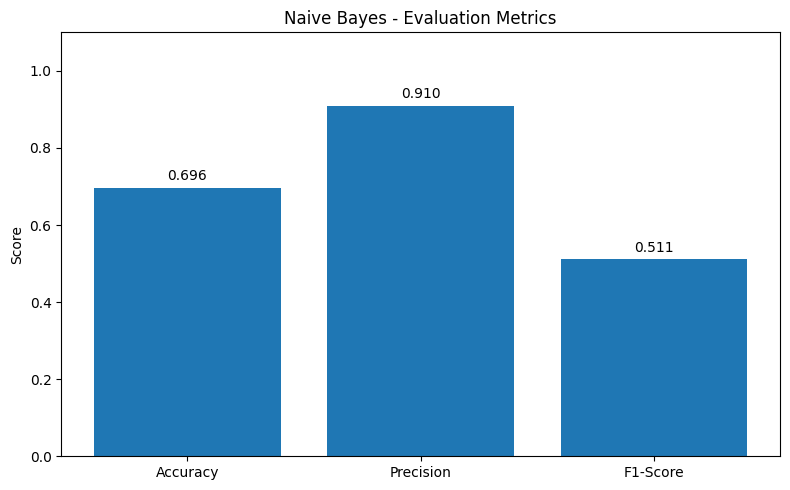

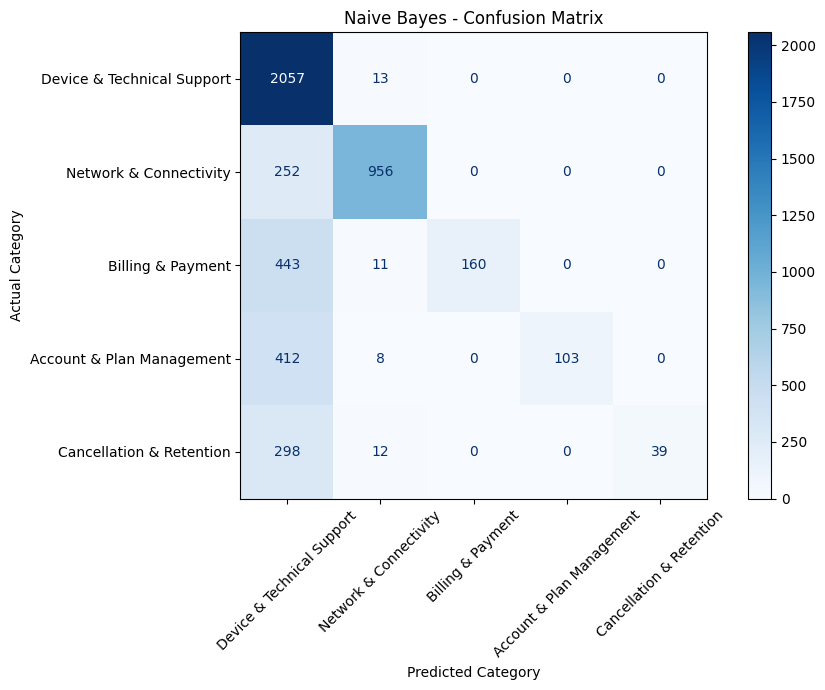

In [32]:

# Naive Bayes - Model Evaluation Visualizations

import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    f1_score,
    ConfusionMatrixDisplay
)

# Calculate evaluation metrics
accuracy = accuracy_score(y_val, nb_predictions)
precision = precision_score(
    y_val, nb_predictions,
    average="macro", zero_division=0
)
f1 = f1_score(
    y_val, nb_predictions,
    average="macro", zero_division=0
)

# 1. Accuracy, Precision, and F1-Score
metrics = ["Accuracy", "Precision", "F1-Score"]
scores = [accuracy, precision, f1]

plt.figure(figsize=(8, 5))
bars = plt.bar(metrics, scores)

plt.title("Naive Bayes - Evaluation Metrics")
plt.ylabel("Score")
plt.ylim(0, 1.1)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        score + 0.02,
        f"{score:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

# 2. Confusion Matrix
fig, ax = plt.subplots(figsize=(10, 7))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    nb_predictions,
    labels=CLASS_ORDER,
    display_labels=CLASS_ORDER,
    cmap="Blues",
    xticks_rotation=45,
    values_format="d",
    ax=ax
)

plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()


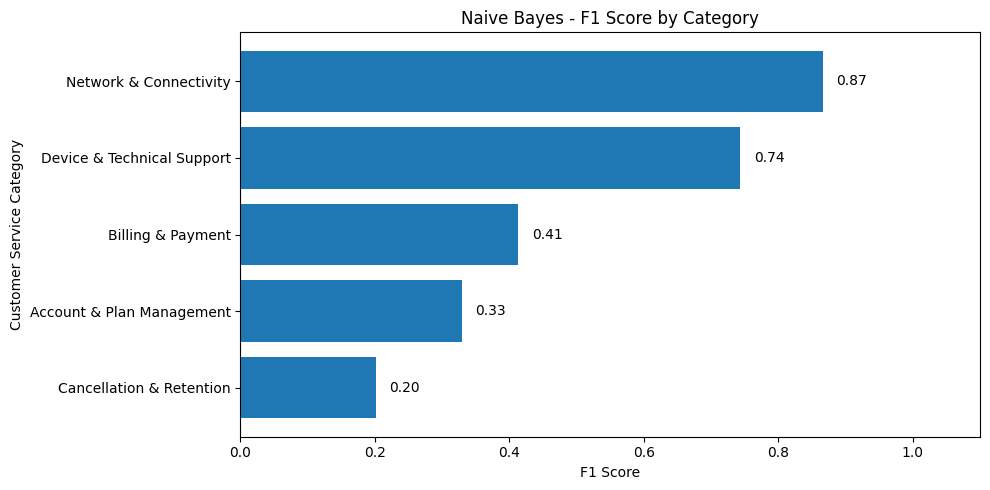

In [33]:

# Naive Bayes - F1 Score by Category

from sklearn.metrics import classification_report
import pandas as pd
import matplotlib.pyplot as plt

report = classification_report(
    y_val,
    nb_predictions,
    labels=CLASS_ORDER,
    output_dict=True,
    zero_division=0
)

f1_scores = pd.Series({
    category: report[category]["f1-score"]
    for category in CLASS_ORDER
}).sort_values()

plt.figure(figsize=(10, 5))

bars = plt.barh(
    f1_scores.index,
    f1_scores.values
)

plt.title("Naive Bayes - F1 Score by Category")
plt.xlabel("F1 Score")
plt.ylabel("Customer Service Category")
plt.xlim(0, 1.1)

for bar in bars:
    plt.text(
        bar.get_width() + 0.02,
        bar.get_y() + bar.get_height()/2,
        f"{bar.get_width():.2f}",
        va="center"
    )

plt.tight_layout()
plt.show()


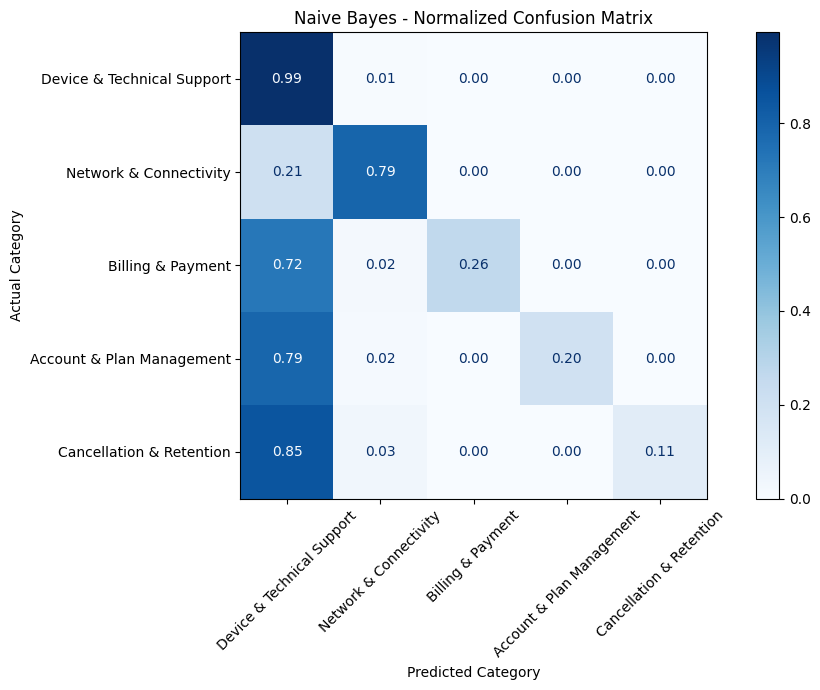

In [34]:

# Naive Bayes - Normalized Confusion Matrix

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 7))

ConfusionMatrixDisplay.from_predictions(
    y_val,
    nb_predictions,
    labels=CLASS_ORDER,
    display_labels=CLASS_ORDER,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
    ax=ax
)

plt.title("Naive Bayes - Normalized Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")

plt.tight_layout()
plt.show()


Device Support: 99% recall, but only 59% precision. The model captures nearly all actual Device Support tweets, but many tweets predicted as Device Support belong to other categories.



Cancellation: Only 11% recall. The model misses approximately 89% of actual cancellation tweets.



Billing: Only 26% recall. The model misses approximately 74% of actual billing tweets.

## Logistic Regression (Weighted)
Train a Logistic Regression model on the same TF-IDF features, using class weights computed from the training split only, and evaluate it on the validation set with the same metrics as Naive Bayes.

In [35]:
# Collect each model's metrics in one place so Task #12 can build the comparison table
results = {}

def evaluate_model(name, y_true, y_pred):
    report = classification_report(
        y_true, y_pred, labels=CLASS_ORDER, output_dict=True, zero_division=0
    )
    results[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        **{f"Recall: {c}": report[c]["recall"] for c in CLASS_ORDER},
    }
    return results[name]

# Add the Naive Bayes results from Task #9
evaluate_model("Naive Bayes", y_val, nb_predictions)

{'Accuracy': 0.6958438287153652,
 'Macro Precision': 0.9100330444829577,
 'Macro Recall': 0.47087708640773007,
 'Macro F1': 0.5106312612027983,
 'Recall: Device & Technical Support': 0.993719806763285,
 'Recall: Network & Connectivity': 0.7913907284768212,
 'Recall: Billing & Payment': 0.26058631921824105,
 'Recall: Account & Plan Management': 0.19694072657743786,
 'Recall: Cancellation & Retention': 0.11174785100286533}

### Train and Evaluate Logistic Regression

In [36]:
# Weighted Logistic Regression: class weights come from the TRAINING split only
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight=weights_dict_train,
    random_state=42
)
lr_model.fit(X_train, y_train)

# Predict validation labels
lr_predictions = lr_model.predict(X_val)

# Same metrics as Naive Bayes
evaluate_model("Logistic Regression", y_val, lr_predictions)
print("Logistic Regression Results")
print("Accuracy:", accuracy_score(y_val, lr_predictions))
print("Macro F1:", f1_score(y_val, lr_predictions, average="macro"))
print("\nClassification Report:")
print(classification_report(y_val, lr_predictions, labels=CLASS_ORDER))

Logistic Regression Results
Accuracy: 0.9911838790931989
Macro F1: 0.9893454401331745

Classification Report:
                            precision    recall  f1-score   support

Device & Technical Support       0.99      0.99      0.99      2070
    Network & Connectivity       1.00      0.99      0.99      1208
         Billing & Payment       0.98      0.99      0.98       614
 Account & Plan Management       1.00      0.99      0.99       523
  Cancellation & Retention       0.99      0.99      0.99       349

                  accuracy                           0.99      4764
                 macro avg       0.99      0.99      0.99      4764
              weighted avg       0.99      0.99      0.99      4764



In [37]:
### Logistic Regression - Evaluation Visualizations

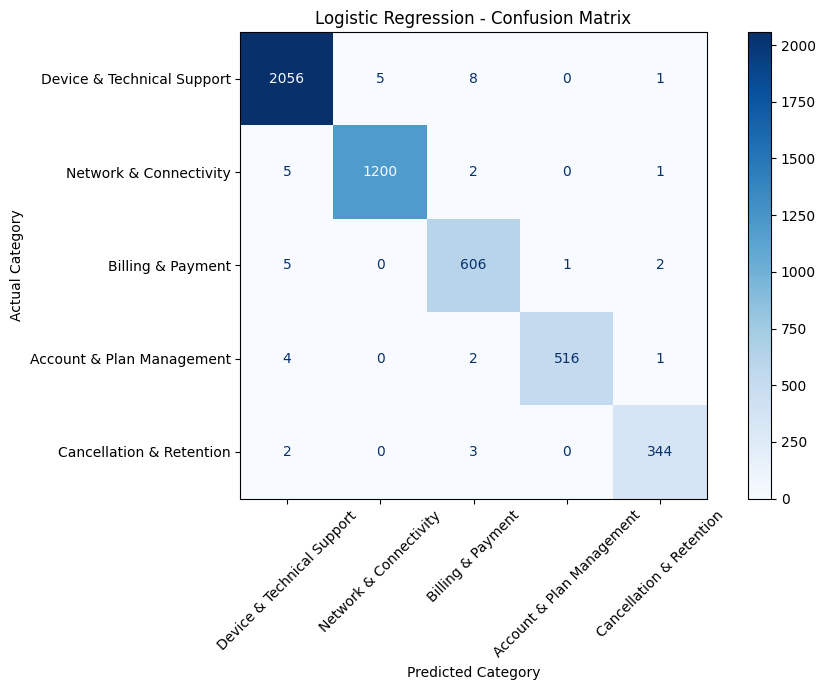

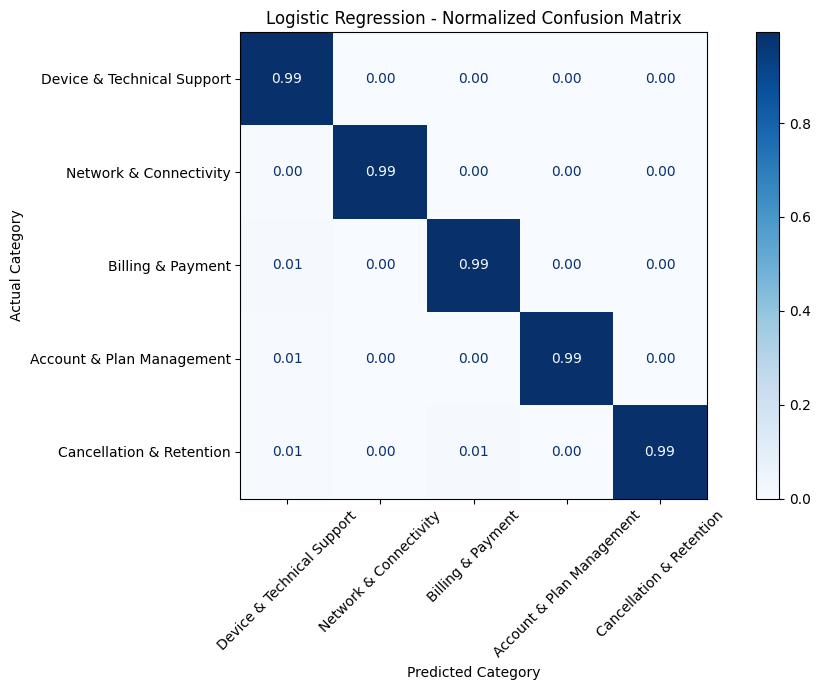

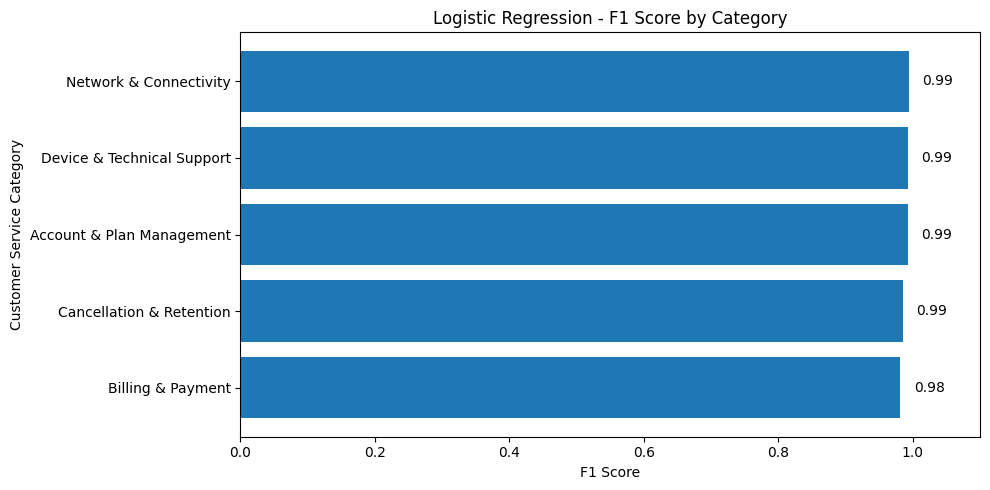

In [38]:
# Confusion matrix (counts)
fig, ax = plt.subplots(figsize=(10, 7))
ConfusionMatrixDisplay.from_predictions(
    y_val, lr_predictions, labels=CLASS_ORDER, display_labels=CLASS_ORDER,
    cmap="Blues", xticks_rotation=45, values_format="d", ax=ax
)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

# Normalized confusion matrix (each row sums to 1, so you can read recall per category)
fig, ax = plt.subplots(figsize=(11, 7))
ConfusionMatrixDisplay.from_predictions(
    y_val, lr_predictions, labels=CLASS_ORDER, display_labels=CLASS_ORDER,
    normalize="true", cmap="Blues", values_format=".2f", xticks_rotation=45, ax=ax
)
plt.title("Logistic Regression - Normalized Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.tight_layout()
plt.show()

# F1 score by category
report = classification_report(y_val, lr_predictions, labels=CLASS_ORDER, output_dict=True, zero_division=0)
f1_scores = pd.Series({c: report[c]["f1-score"] for c in CLASS_ORDER}).sort_values()

plt.figure(figsize=(10, 5))
bars = plt.barh(f1_scores.index, f1_scores.values)
plt.title("Logistic Regression - F1 Score by Category")
plt.xlabel("F1 Score")
plt.ylabel("Customer Service Category")
plt.xlim(0, 1.1)
for bar in bars:
    plt.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height() / 2,
             f"{bar.get_width():.2f}", va="center")
plt.tight_layout()
plt.show()

### Logistic Regression Findings
- Weighted Logistic Regression reached 0.991 accuracy and 0.989 macro F1 on the validation set, with macro precision of 0.990 and macro recall of 0.989.
- Recall is high for every category: Device & Technical Support 0.993, Network & Connectivity 0.993, Billing & Payment 0.987, Account & Plan Management 0.987 and Cancellation & Retention 0.986.
- Compared with Naive Bayes (0.696 accuracy, 0.511 macro F1), the largest gains are in the smaller categories. Cancellation recall rose from 0.11 to 0.986 and Billing recall from 0.26 to 0.987.
- These scores are likely inflated because the labels appear to follow keywords. Validation performance should not be read as expected performance on new customer tweets.

In [40]:

# Task 8: Train Random Forest

rf_model = RandomForestClassifier(
    #since training is taking too long, we reduced from 100 to 50
    n_estimators=50,
    class_weight=weights_dict_train,
    random_state=42,
    n_jobs=-1
)

# Train using training data only
rf_model.fit(X_train, y_train)

# Predict validation labels
rf_predictions = rf_model.predict(X_val)

# Save evaluation metrics using our existing function
evaluate_model("Random Forest", y_val, rf_predictions)

# Display results
print("Random Forest Results")
print("Accuracy:", accuracy_score(y_val, rf_predictions))
print("Macro F1:", f1_score(
    y_val, rf_predictions, average="macro"
))

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_predictions,
    labels=CLASS_ORDER,
    zero_division=0
))


Random Forest Results
Accuracy: 0.966414777497901
Macro F1: 0.9604875376674273

Classification Report:
                            precision    recall  f1-score   support

Device & Technical Support       0.94      1.00      0.97      2070
    Network & Connectivity       0.98      0.98      0.98      1208
         Billing & Payment       0.99      0.92      0.95       614
 Account & Plan Management       1.00      0.93      0.96       523
  Cancellation & Retention       1.00      0.88      0.94       349

                  accuracy                           0.97      4764
                 macro avg       0.98      0.94      0.96      4764
              weighted avg       0.97      0.97      0.97      4764



,Accuracy,Macro Precision,Macro Recall,Macro F1,Recall: Device & Technical Support,Recall: Network & Connectivity,Recall: Billing & Payment,Recall: Account & Plan Management,Recall: Cancellation & Retention
Logistic Regression,0.991,0.990,0.989,0.989,0.993,0.993,0.987,0.987,0.986
Random Forest,0.966,0.982,0.942,0.960,0.995,0.981,0.919,0.931,0.883
Naive Bayes,0.696,0.910,0.471,0.511,0.994,0.791,0.261,0.197,0.112


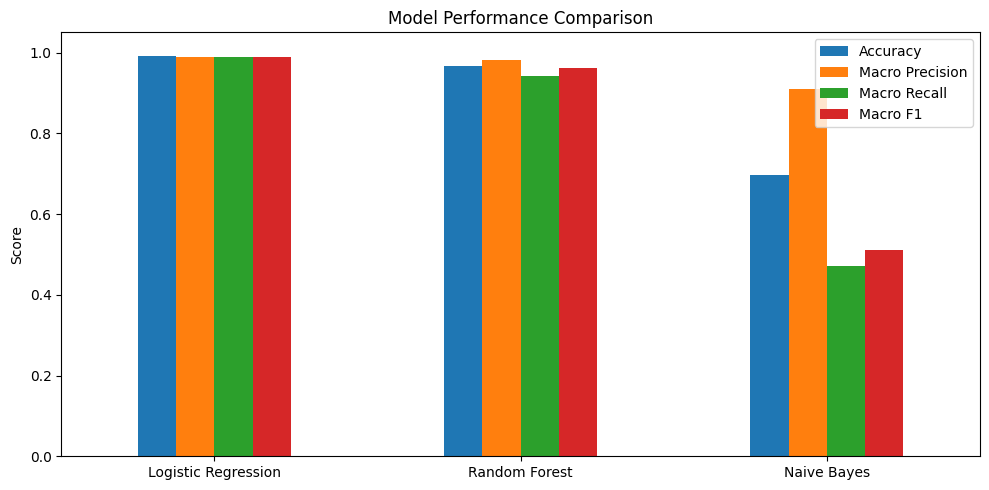

In [41]:

# Task 8: Compare all three models

comparison_df = pd.DataFrame.from_dict(
    results,
    orient="index"
)

# Sort models by Macro F1
comparison_df = comparison_df.sort_values(
    by="Macro F1",
    ascending=False
)

display(comparison_df.round(3))

# Compare overall metrics
comparison_df[
    ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]
].plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1.05),
    rot=0,
    title="Model Performance Comparison"
)

plt.ylabel("Score")
plt.tight_layout()
plt.show()


,Device & Technical Support,Network & Connectivity,Billing & Payment,Account & Plan Management,Cancellation & Retention
Logistic Regression,0.993,0.993,0.987,0.987,0.986
Random Forest,0.995,0.981,0.919,0.931,0.883
Naive Bayes,0.994,0.791,0.261,0.197,0.112


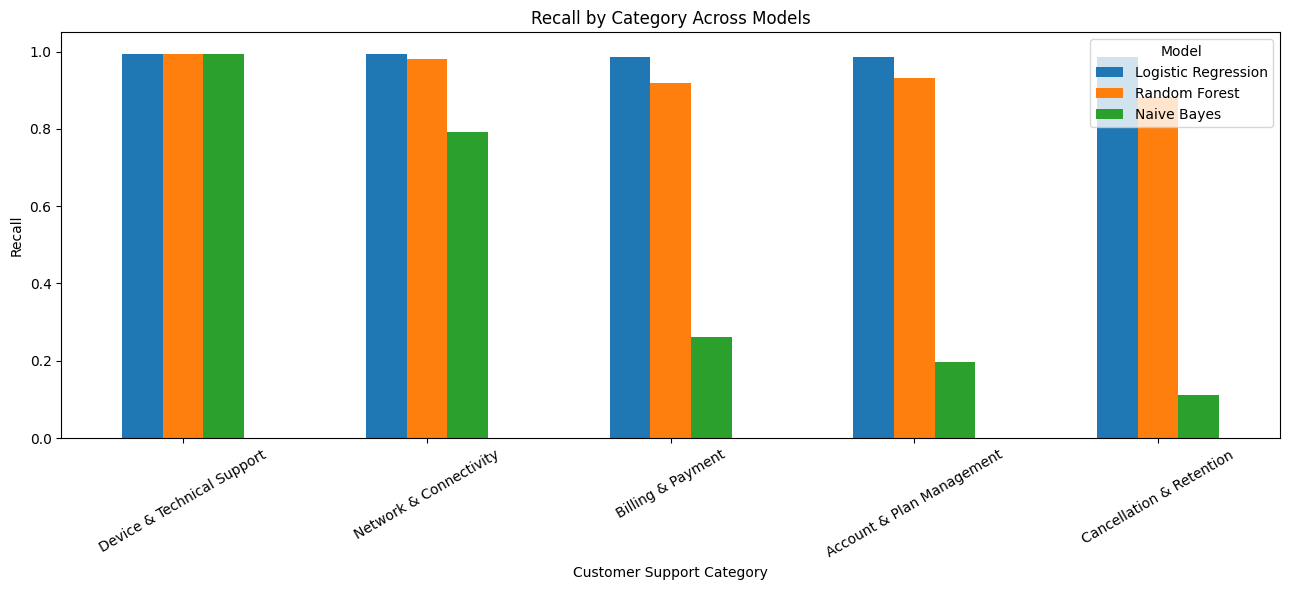

In [42]:

# Compare recall by customer support category

recall_columns = [
    f"Recall: {category}"
    for category in CLASS_ORDER
]

recall_comparison = comparison_df[recall_columns].copy()
recall_comparison.columns = CLASS_ORDER

display(recall_comparison.round(3))

recall_comparison.T.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1.05),
    rot=30,
    title="Recall by Category Across Models"
)

plt.ylabel("Recall")
plt.xlabel("Customer Support Category")
plt.legend(title="Model")
plt.tight_layout()
plt.show()


In [43]:

from sklearn.metrics import confusion_matrix

predictions = {
    "Naive Bayes": nb_predictions,
    "Logistic Regression": lr_predictions,
    "Random Forest": rf_predictions
}

for name, y_pred in predictions.items():
    cm = confusion_matrix(
        y_val, y_pred, labels=CLASS_ORDER
    )

    # Exclude correct predictions
    np.fill_diagonal(cm, 0)

    errors = []

    for i, actual in enumerate(CLASS_ORDER):
        for j, predicted in enumerate(CLASS_ORDER):
            if cm[i, j] > 0:
                errors.append({
                    "Actual": actual,
                    "Predicted": predicted,
                    "Count": cm[i, j]
                })

    print(f"\n{name} - Most Frequent Confusions")

    if errors:
        error_df = pd.DataFrame(errors)
        display(
            error_df.sort_values(
                "Count", ascending=False
            ).head(5)
        )
    else:
        print("No misclassifications.")



Naive Bayes - Most Frequent Confusions


,Actual,Predicted,Count
2,Billing & Payment,Device & Technical Support,443
4,Account & Plan Management,Device & Technical Support,412
6,Cancellation & Retention,Device & Technical Support,298
1,Network & Connectivity,Device & Technical Support,252
0,Device & Technical Support,Network & Connectivity,13



Logistic Regression - Most Frequent Confusions


,Actual,Predicted,Count
1,Device & Technical Support,Billing & Payment,8
0,Device & Technical Support,Network & Connectivity,5
3,Network & Connectivity,Device & Technical Support,5
6,Billing & Payment,Device & Technical Support,5
9,Account & Plan Management,Device & Technical Support,4



Random Forest - Most Frequent Confusions


,Actual,Predicted,Count
3,Billing & Payment,Device & Technical Support,42
5,Account & Plan Management,Device & Technical Support,32
7,Cancellation & Retention,Device & Technical Support,29
2,Network & Connectivity,Device & Technical Support,23
8,Cancellation & Retention,Network & Connectivity,11


### Task #8 Findings

We trained and evaluated three classification models: Multinomial Naive Bayes, Logistic Regression, and Random Forest. All three models used TF-IDF features, and class weights for Logistic Regression and Random Forest were calculated using only the training data. Random Forest was trained with 50 estimators instead of 100 to reduce training time.

**Model Performance:**
- **Naive Bayes:** Achieved 69.6% accuracy and 0.511 macro F1. Although it performed well on Device & Technical Support, it struggled with Billing & Payment, Account & Plan Management, and Cancellation & Retention.
- **Logistic Regression:** Achieved 99.1% accuracy and 0.989 macro F1, with recall above 98% across all five categories.
- **Random Forest:** Achieved 96.6% accuracy and 0.960 macro F1. It performed well overall but had lower recall for Cancellation & Retention (0.883) and Billing & Payment (0.919).

**Classification Errors:**

The confusion analysis showed that Naive Bayes frequently classified other customer issues as Device & Technical Support. This included 443 Billing & Payment cases, 412 Account & Plan Management cases, and 298 Cancellation & Retention cases.

Random Forest showed a similar pattern but with substantially fewer errors. Logistic Regression had the fewest classification errors overall, with its largest individual confusion involving eight Device & Technical Support cases classified as Billing & Payment.

**Key Observation:**

Logistic Regression had the highest macro F1 and the most balanced recall across all five categories. This is especially important because our dataset contains an uneven distribution of customer-support categories, making accuracy alone an insufficient measure of performance.

However, the unusually high validation scores may be influenced by the keyword-derived labeling process. Because the models may be learning patterns associated with the labeling rules, these results do not necessarily reflect performance on independently labeled customer-support messages.

### Task #8 Conclusion

Based on validation results, **Logistic Regression was selected as our best provisional classification model**, achieving 99.1% accuracy and a macro F1-score of 0.989.

It outperformed both Naive Bayes and Random Forest while maintaining consistently high recall across all five customer-support categories.

Random Forest was the second-best model, with a macro F1-score of 0.960, while Naive Bayes performed considerably worse, particularly on the less-represented categories.

Although Logistic Regression produced strong results, the keyword-labeling limitation means that additional evaluation using independently labeled customer-support messages would be necessary before considering the model ready for real-world deployment.

The independent test dataset was left untouched throughout model training, validation, and model selection to preserve it for final evaluation.

In [44]:

# Select provisional best model based on validation Macro F1

best_model = comparison_df["Macro F1"].idxmax()

print("Best Provisional Model:", best_model)
print(
    "Validation Macro F1:",
    round(comparison_df.loc[best_model, "Macro F1"], 3)
)

print("\nIndependent test set remains untouched.")


Best Provisional Model: Logistic Regression
Validation Macro F1: 0.989

Independent test set remains untouched.
